# 11 · Ensemble dengan Neural Network

Menggabungkan hasil Kaggle (notebook 10: RealMLP, TabM, TabICL) dengan anggota ensemble yang sudah ada (notebook 07).

**Pembanding = ensemble saat ini**, yaitu rata-rata peringkat bobot sama dari `lgbm_tuned`, `xgb_v1`, `cat_v1`, `logreg_v1` (dasar `sub_v4`). Karena kedua sisi sama-sama ensemble, perbandingan **per seed** sekarang adil. Di notebook 07, ensemble dibandingkan dengan satu model tunggal, sehingga Δ per seed terlalu menguntungkan ensemble.

Pertanyaan yang dijawab:
1. Seberapa kuat & seberapa **berbeda** model NN dibanding anggota yang ada?
2. Apakah menambah satu/semua model NN ke ensemble menaikkan KS secara konsisten?
3. Apakah bobot "optimal" (dinilai jujur dengan validasi bersarang) mengalahkan bobot sama?

**Persiapan:** ekstrak `nn_runs.zip` dari Kaggle ke folder `data/preds/`. Di sana harus ada file `realmlp_v1_*`, `tabm_v1_*`, dan/atau `tabicl_v1_*`.

Aturan keputusan sama: **jelas** (Δ ≥ 0,005) / **tipis** (Δ ≥ 0,002), semua seed naik. Kandidat yang hanya punya 1 seed (misalnya TabICL) ditandai **"perlu seed tambahan"** dan tidak bisa lolos sebelum dijalankan dengan 3 seed.

In [1]:
import json
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E
import modeling as M

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

train = pl.read_parquet(M.FEAT_DIR / "train_v1.parquet")
test = pl.read_parquet(M.FEAT_DIR / "test_v1.parquet")
y = train["target"].to_numpy()
SEG = train["segment"].to_numpy()

CORE = {"lgbm": "lgbm_tuned", "xgb": "xgb_v1", "cat": "cat_v1", "logreg": "logreg_v1"}
NN = {"realmlp": "realmlp_v1", "tabm": "tabm_v1", "tabicl": "tabicl_v1"}
RUNS = {k: M.run_from_disk(v, y) for k, v in CORE.items()}
for k, v in NN.items():
    if (M.PRED_DIR / f"{v}_meta.json").exists():
        r = M.run_from_disk(v, y)
        assert pl.read_parquet(M.PRED_DIR / f"{v}_oof.parquet")["application_id"].equals(train["application_id"])
        RUNS[k] = r
NN_AVAIL = [k for k in NN if k in RUNS]
print("Anggota inti:", list(CORE), "| NN tersedia:", NN_AVAIL or "belum ada — ekstrak nn_runs.zip ke data/preds/")
for k in NN_AVAIL:
    print(f"  {k}: seed {RUNS[k]['seeds']}")

Anggota inti: ['lgbm', 'xgb', 'cat', 'logreg'] | NN tersedia: ['realmlp', 'tabm', 'tabicl']
  realmlp: seed [42, 7, 2024]
  tabm: seed [42, 7, 2024]
  tabicl: seed [42, 7, 2024]


## 1. Kekuatan & keberagaman

KS dihitung pada seed yang dimiliki model itu. Korelasi peringkat dihitung terhadap `lgbm` dan terhadap **ensemble saat ini** pada seed 42. Anggota baru yang berguna biasanya cukup kuat **dan** korelasinya dengan ensemble saat ini paling rendah.

In [2]:
REF_SEEDS = [s for s in (42, 7, 2024) if all(s in RUNS[k]["seeds"] for k in CORE)]
REF = M.blend({k: RUNS[k] for k in CORE}, y, seeds=REF_SEEDS)          # ensemble saat ini (sub_v4)
ref42 = M.rank01(REF["oof_by_seed"][42])
rows = []
for k, r in RUNS.items():
    s = [x for x in REF_SEEDS if x in r["seeds"]]
    rows.append(dict(model=k, jenis="NN" if k in NN else "inti", seed=len(s),
                     ks_rata2_per_seed=np.mean([r["ks_by_seed"][x] for x in s]),
                     ks_oof_gabungan=M.ks_score(y, np.mean([r["oof_by_seed"][x] for x in s], axis=0)),
                     korelasi_dgn_lgbm=np.corrcoef(M.rank01(r["oof_by_seed"][42]), M.rank01(RUNS["lgbm"]["oof_by_seed"][42]))[0, 1],
                     korelasi_dgn_ensemble=np.corrcoef(M.rank01(r["oof_by_seed"][42]), ref42)[0, 1]))
rows.append(dict(model="ENSEMBLE SAAT INI", jenis="ref", seed=len(REF_SEEDS),
                 ks_rata2_per_seed=np.mean(list(REF["ks_by_seed"].values())), ks_oof_gabungan=REF["ks_oof"],
                 korelasi_dgn_lgbm=np.corrcoef(ref42, M.rank01(RUNS["lgbm"]["oof_by_seed"][42]))[0, 1], korelasi_dgn_ensemble=1.0))
pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))

model,jenis,seed,ks_rata2_per_seed,ks_oof_gabungan,korelasi_dgn_lgbm,korelasi_dgn_ensemble
str,str,i64,f64,f64,f64,f64
"""lgbm""","""inti""",3,0.5208,0.5238,1.0,0.9956
"""xgb""","""inti""",3,0.5194,0.522,0.9899,0.9935
"""cat""","""inti""",3,0.5178,0.5207,0.9867,0.9919
"""logreg""","""inti""",3,0.5176,0.5186,0.9694,0.9825
"""realmlp""","""NN""",3,0.5212,0.5226,0.9843,0.9869
"""tabm""","""NN""",3,0.5189,0.521,0.9829,0.9863
"""tabicl""","""NN""",3,0.5143,0.5148,0.9721,0.9776
"""ENSEMBLE SAAT INI""","""ref""",3,0.5237,0.5254,0.9956,1.0


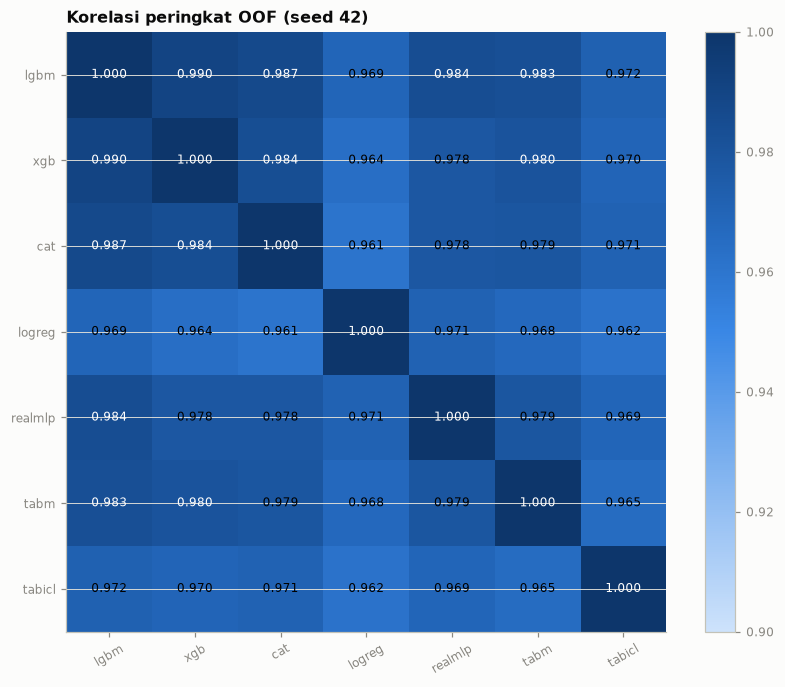

In [3]:
names = list(RUNS)
C = np.corrcoef([M.rank01(RUNS[k]["oof_by_seed"][42]) for k in names])
fig, ax = plt.subplots(figsize=(0.75 * len(names) + 2.5, 0.65 * len(names) + 1.8))
im = ax.imshow(C, cmap=E.SEQ_CMAP, vmin=min(0.9, C.min()), vmax=1)
ax.set_xticks(range(len(names)), names, rotation=30); ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{C[i, j]:.3f}", ha="center", va="center", fontsize=8,
                color="white" if C[i, j] > (C.min() + 1) / 2 else "black")
ax.set_title("Korelasi peringkat OOF (seed 42)", loc="left")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

## 2. Menambah model NN ke ensemble (bobot sama)

In [4]:
CANDS = {}
for k in NN_AVAIL:
    CANDS[f"ensemble + {k}"] = [*CORE, k]
if len(NN_AVAIL) > 1:
    CANDS["ensemble + semua NN"] = [*CORE, *NN_AVAIL]
    nn_multi = [k for k in NN_AVAIL if len([s for s in REF_SEEDS if s in RUNS[k]["seeds"]]) >= 3]
    if 1 < len(nn_multi) < len(NN_AVAIL):
        CANDS["ensemble + NN (3 seed saja)"] = [*CORE, *nn_multi]
BL, CMP = {}, {}
for n, members in CANDS.items():
    seeds = [s for s in REF_SEEDS if all(s in RUNS[m]["seeds"] for m in members)]
    BL[n] = M.blend({m: RUNS[m] for m in members}, y, seeds=seeds)
    CMP[n] = M.compare_runs(REF, BL[n], y, SEG)

def tbl(keys):
    out = []
    for n in keys:
        c = CMP[n]; ns = c["per_seed"].height
        v = M.verdict(c, noise=0.0015) if ns >= 3 else "perlu seed tambahan"
        out.append(dict(kandidat=n, seed=ns, delta_oof_gabungan=c["delta_oof"],
                        **{f"d_s{s}": d for s, d in zip(c["per_seed"]["seed"], c["per_seed"]["delta"])},
                        delta_rata2=c["delta_seed_mean"], seed_naik=f"{c['n_seed_positive']}/{ns}", keputusan=v))
    return pl.DataFrame(out).with_columns(pl.col(pl.Float64).round(4))

tbl(list(CANDS)) if CANDS else print("Belum ada run NN.")

kandidat,seed,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,i64,f64,f64,f64,f64,f64,str,str
"""ensemble + realmlp""",3,0.0002,0.0001,0.0006,0.0005,0.0004,"""3/3""","""tidak"""
"""ensemble + tabm""",3,-0.0001,0.0003,-0.001,0.0013,0.0002,"""2/3""","""tidak"""
"""ensemble + tabicl""",3,-0.001,-0.0009,-0.0004,0.0001,-0.0004,"""1/3""","""tidak"""
"""ensemble + semua NN""",3,-0.001,0.0007,0.0003,0.0005,0.0005,"""3/3""","""tidak"""


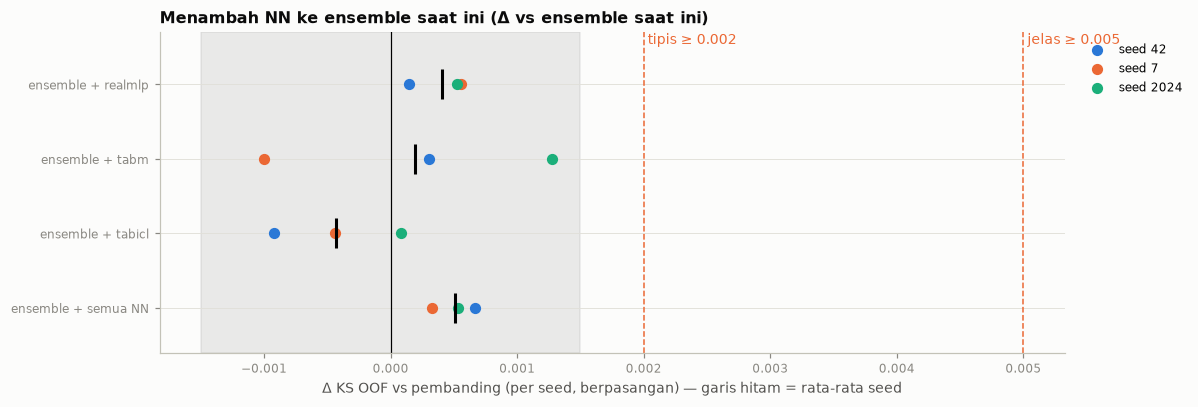

In [5]:
if CANDS:
    M.plot_paired_deltas(CMP, list(CANDS), noise=0.0015, title="Menambah NN ke ensemble saat ini (Δ vs ensemble saat ini)")

## 3. Bobot optimal: tampak vs jujur

Dicari di grid kelipatan 0,1 (0,2 bila anggota > 5; bobot `lgbm` minimal 0,1), memakai anggota yang punya ≥ 3 seed. Versi **jujur** memilih bobot di 4/5 baris dan menilainya di 1/5 sisanya, bergiliran.

In [6]:
MULTI = [k for k in RUNS if len([s for s in REF_SEEDS if s in RUNS[k]["seeds"]]) >= 3]
if len(MULTI) > len(CORE):
    sub = {k: RUNS[k] for k in MULTI}
    STEP = 0.1 if len(MULTI) <= 5 else 0.2          # grid lebih kasar bila anggota banyak (jumlah kombinasi meledak)
    W_IN, _ = M.best_weights(sub, y, "lgbm", REF_SEEDS, step=STEP, max_other=0.9)
    BL["bobot optimal (tampak)"] = M.blend(sub, y, weights=W_IN, seeds=REF_SEEDS)
    CMP["bobot optimal (tampak)"] = M.compare_runs(REF, BL["bobot optimal (tampak)"], y, SEG)
    BL["bobot optimal (jujur)"] = M.nested_blend(sub, y, "lgbm", seeds=REF_SEEDS, step=STEP, max_other=0.9)
    CMP["bobot optimal (jujur)"] = M.compare_runs(REF, BL["bobot optimal (jujur)"], y, SEG)
    print("Bobot optimal di seluruh OOF:", {k: round(float(v), 2) for k, v in W_IN.items()})
    display(tbl(["bobot optimal (tampak)", "bobot optimal (jujur)"]))
    print("Bobot per fold (validasi bersarang):")
    display(BL["bobot optimal (jujur)"]["fold_weights"])
else:
    print("Butuh minimal satu model NN dengan 3 seed.")

Bobot optimal di seluruh OOF: {'lgbm': 0.2, 'xgb': 0.2, 'cat': 0.0, 'logreg': 0.2, 'realmlp': 0.4, 'tabm': 0.0, 'tabicl': 0.0}


kandidat,seed,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan
str,i64,f64,f64,f64,f64,f64,str,str
"""bobot optimal (tampak)""",3,-0.0005,0.0006,0.0004,0.0016,0.0009,"""3/3""","""tidak"""
"""bobot optimal (jujur)""",3,-0.0012,-0.0011,-0.0022,0.0009,-0.0008,"""1/3""","""tidak"""


Bobot per fold (validasi bersarang):


seed,lgbm,xgb,cat,logreg,realmlp,tabm,tabicl
i64,f64,f64,f64,f64,f64,f64,f64
42,0.4,0.0,0.0,0.2,0.2,0.2,0.0
42,0.2,0.0,0.4,0.2,0.0,0.0,0.2
42,0.2,0.0,0.4,0.2,0.0,0.2,0.0
42,0.2,0.0,0.2,0.4,0.0,0.2,0.0
42,0.2,0.0,0.4,0.2,0.0,0.2,0.0
7,0.2,0.2,0.2,0.0,0.2,0.2,0.0
7,0.2,0.0,0.0,0.0,0.4,0.4,0.0
7,0.2,0.0,0.0,0.4,0.4,0.0,0.0
7,0.2,0.0,0.0,0.4,0.4,0.0,0.0


## 4. Keputusan & submission

In [7]:
pool = [n for n in BL if n != "bobot optimal (tampak)" and CMP[n]["per_seed"].height >= 3]
if pool:
    BEST = max(pool, key=lambda n: CMP[n]["delta_oof"])
    V = M.verdict(CMP[BEST], noise=0.0015)
    print(f"Kandidat terbaik: {BEST} | Δ OOF gabungan {CMP[BEST]['delta_oof']:+.4f} | Δ per seed "
          f"{[round(d, 4) for d in CMP[BEST]['per_seed']['delta']]} | keputusan: {V}")
    display(CMP[BEST]["per_segment"].with_columns(pl.col(pl.Float64).round(4)))
    if V in ("jelas", "tipis"):
        final = M.blend({m: RUNS[m] for m in MULTI}, y, weights=W_IN, seeds=REF_SEEDS) if BEST == "bobot optimal (jujur)" else BL[BEST]
        final.update(features=[], params=final.get("weights", {}), best_iters=[0])
        M.save_run("ensemble_nn_v1", train, test, final, extra=dict(blend=BEST, weights=final.get("weights"),
                                                                     delta_vs_ensemble_v1=CMP[BEST]["delta_oof"]))
        ss = pl.read_parquet(E.PQ_DIR / "sample_submission.parquet")
        M.make_submission(test["application_id"], final["test_pred"], ss, M.SUB_DIR / "sub_v5_ensemble_nn.csv")
        r = np.corrcoef(M.rank01(final["test_pred"]), M.rank01(REF["test_pred"]))[0, 1]
        print(f"Korelasi peringkat prediksi test vs ensemble saat ini: {r:.4f}")
    else:
        print("Tidak lolos → ensemble saat ini (sub_v4) tetap dipakai.")
else:
    print("Belum ada kandidat dengan ≥ 3 seed.")

Kandidat terbaik: ensemble + realmlp | Δ OOF gabungan +0.0002 | Δ per seed [0.0001, 0.0006, 0.0005] | keputusan: tidak


segment,n,ks_base,ks_baru,delta
str,i64,f64,f64,f64
"""SEMUA""",70000,0.5254,0.5255,0.0002
"""A_no_history""",21000,0.495,0.496,0.0011
"""B_apps_no_installments""",2688,0.5287,0.5325,0.0038
"""C_has_installments""",46312,0.5384,0.5392,0.0009


Tidak lolos → ensemble saat ini (sub_v4) tetap dipakai.
